In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/turbofan-rul/'
DATA = BASE + 'data/'
RESULTS = BASE + 'results/'

Mounted at /content/drive


In [2]:
train = pd.read_csv(DATA + 'train_FD001_clean.csv')

cols = ['engine', 'cycle', 'setting1', 'setting2', 'setting3'] + [f's{i}' for i in range(1, 22)]
test = pd.read_csv(DATA + 'test_FD001.txt', sep=r'\s+', header=None)
test.columns = cols

rul_true = pd.read_csv(DATA + 'RUL_FD001.txt', header=None)[0].values
print(train.shape, test.shape, rul_true.shape)

(20631, 29) (13096, 26) (100,)


In [3]:
flat = ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
features = [f's{i}' for i in range(1, 22) if f's{i}' not in flat]
print(len(features), features)

14 ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


In [4]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, va_idx = next(gss.split(train, groups=train['engine']))
tr = train.iloc[tr_idx]
va = train.iloc[va_idx]

print(tr['engine'].nunique(), va['engine'].nunique())
print(set(tr['engine']) & set(va['engine']))

80 20
set()


In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(tr[features])

X_tr = scaler.transform(tr[features]);  y_tr = tr['RUL_capped'].values
X_va = scaler.transform(va[features]);  y_va = va['RUL_capped'].values

test_last = test.groupby('engine').tail(1)      # last row of each test engine
X_te = scaler.transform(test_last[features])
y_te = np.minimum(rul_true, 125)                # same cap of 125 as training

In [6]:
def rmse(y, p):
    return float(np.sqrt(np.mean((p - y) ** 2)))

def nasa_score(y, p):
    d = p - y
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

In [7]:
results = []

def evaluate(name, model, Xtr=X_tr, Xva=X_va, Xte=X_te):
    model.fit(Xtr, y_tr)
    p_va = np.clip(model.predict(Xva), 0, 125)
    p_te = np.clip(model.predict(Xte), 0, 125)
    row = {'model': name,
           'val_RMSE': rmse(y_va, p_va),
           'test_RMSE': rmse(y_te, p_te),
           'test_NASA_score': nasa_score(y_te, p_te)}
    results.append(row)
    print(row)

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

evaluate('Naive (mean)', DummyRegressor())
evaluate('Linear Regression', LinearRegression())
evaluate('Random Forest', RandomForestRegressor(
    n_estimators=100, max_depth=12, min_samples_leaf=5, n_jobs=2, random_state=42))
evaluate('XGBoost', XGBRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=4, n_jobs=2, random_state=42))

{'model': 'Naive (mean)', 'val_RMSE': 41.72082538935907, 'test_RMSE': 41.9802102254234, 'test_NASA_score': 33780.970632786906}
{'model': 'Linear Regression', 'val_RMSE': 19.89992793858531, 'test_RMSE': 20.546564633570753, 'test_NASA_score': 1209.1558698279714}
{'model': 'Random Forest', 'val_RMSE': 16.981753964684962, 'test_RMSE': 17.065071833858926, 'test_NASA_score': 896.6639140945862}
{'model': 'XGBoost', 'val_RMSE': 16.912273403803024, 'test_RMSE': 17.10533427357661, 'test_NASA_score': 965.9633305069136}


In [9]:
res = pd.DataFrame(results).round(2)
res.to_csv(RESULTS + 'baseline_results.csv', index=False)
res

,model,val_RMSE,test_RMSE,test_NASA_score
0,Naive (mean),41.72,41.98,33780.97
1,Linear Regression,19.90,20.55,1209.16
2,Random Forest,16.98,17.07,896.66
3,XGBoost,16.91,17.11,965.96


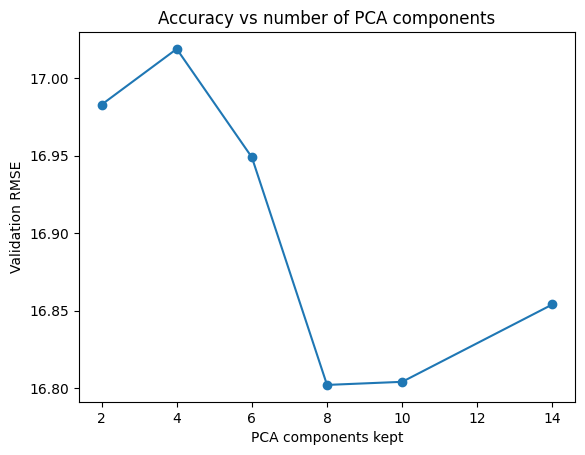

In [10]:
from sklearn.decomposition import PCA

rows = []
for k in [2, 4, 6, 8, 10, 14]:
    pca = PCA(n_components=k).fit(X_tr)
    m = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                     n_jobs=2, random_state=42)
    m.fit(pca.transform(X_tr), y_tr)
    p = np.clip(m.predict(pca.transform(X_va)), 0, 125)
    rows.append({'components': k,
                 'val_RMSE': rmse(y_va, p),
                 'variance_kept': pca.explained_variance_ratio_.sum()})

pca_df = pd.DataFrame(rows).round(3)
pca_df.to_csv(RESULTS + 'pca_results.csv', index=False)
pca_df

plt.plot(pca_df['components'], pca_df['val_RMSE'], marker='o')
plt.xlabel('PCA components kept'); plt.ylabel('Validation RMSE')
plt.title('Accuracy vs number of PCA components')
plt.savefig(RESULTS + 'pca_curve.png', dpi=150)
plt.show()